# Stochastic Gradient Descent, the Perceptron and Activation Functions

**What we have so far:** loss functions (MSE, cross-entropy), gradients, and gradient descent.

**Today:**

1. **Stochastic Gradient Descent (SGD)**: why we rarely use *all* the data for every step, and what happens when we don't.
2. **The Perceptron**: the first "neural network" (Rosenblatt, 1958). Its learning rule turns out to be SGD.
3. **The XOR problem**: four points that a perceptron can never separate (Minsky & Papert, 1969).
4. **Two ways out**: a hand-made *feature map*, and a *hidden layer* with a *non-linear activation function*.
5. **Activation functions**: step, sigmoid, tanh, ReLU, at a glance.

Everything is written in plain NumPy so we can see exactly what happens under the hood.Next week we move to PyTorch, so get ready for some real fun!

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import ListedColormap
from IPython.display import HTML

In [2]:
# As usual, set a bunch of parameters for plotting
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["animation.embed_limit"] = 50  # MB, for the animation later

# Part 1: Stochastic Gradient Descent

## 1.1 Back to our regression problem

We use a simple economics example: **hourly wage** (€) as a function of **years of university**.
The data is simulated, so we know the true relationship:

$$\text{wage} = 10 + 3 \cdot \text{years} + \text{noise}$$

Our model has two parameters, an intercept $b$ and a slope $w$:

$$\hat{y} = b + w \cdot x$$

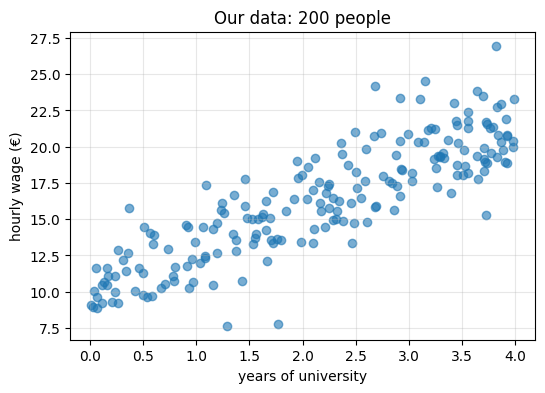

In [3]:
rng = np.random.default_rng(0)

# the number of people in our sample
n = 200
# years of university (between 0 and 4)
x = rng.uniform(0, 4, size=n)
# hourly wage, with random noise
y = 10 + 3 * x + rng.normal(0, 2, size=n)

plt.figure(figsize=(6, 4))
plt.scatter(x, y, alpha=0.6)
plt.xlabel("years of university")
plt.ylabel("hourly wage (€)")
plt.title("Our data: 200 people")
plt.show()

**NumPy Notes** `rng.uniform(0, 4, size=n)` creates an *array* of 200 random numbers.
> Operations like `3 * x` or `y - y_hat` work on **every element at once**, so we never need a loop over people.
> `np.mean(...)` averages all elements of an array.

The same three functions as in the gradient descent notebook (Previous Weeks): MSE loss, and its gradient (Partial Derivatives)

$$L(b, w) = \frac{1}{n}\sum_{i=1}^{n} (y_i - b - w x_i)^2
\qquad
\frac{\partial L}{\partial b} = -\frac{2}{n}\sum_{i} (y_i - \hat y_i)
\qquad
\frac{\partial L}{\partial w} = -\frac{2}{n}\sum_{i} (y_i - \hat y_i)\, x_i$$

In [5]:
# Define three functions: Predict, MSE and the gradient
def predict(x, b, w):
    return b + w * x

def mse(x, y, b, w):
    return np.mean((y - predict(x, b, w)) ** 2)

def gradient(x, y, b, w):
    error = y - predict(x, b, w)
    grad_b = -2 * np.mean(error)
    grad_w = -2 * np.mean(error * x)
    return grad_b, grad_w

## 1.2 The problem with (full-batch) gradient descent

Look at `gradient(x, y, b, w)`: to take **one** step, it goes through **all** $n$ data points.

With 200 people this is nothing. But real datasets have millions of observations (all transactions of a bank, all households in a census, all images on the internet). Computing the exact gradient over all of them, just to take *one small step*, is very wasteful, and the chance of getting stuck in a local minima is too high. Recall that the results of GD depend on the starting point.

**The idea of Stochastic Gradient Descent (SGD):** estimate the gradient from a small random sample of the data, a **mini-batch**, also known as **batch**, and take a step right away.

* The estimate is **noisy**, but on average it points in the right direction (it is an *unbiased* estimate, just like a sample mean estimates the population mean).
* Each step is **much cheaper**, so we can take **many more** steps.

For a accessible discussion of GD, SGD and other algorithms read this nice article:

https://arxiv.org/abs/1609.04747

Vocabulary:

| term | meaning |
|---|---|
| **batch size** | how many data points we use to estimate one gradient |
| **iteration** (or update) | one step of the parameters |
| **epoch** | one full pass over the whole dataset |

| method | batch size | updates per epoch (n = 200) |
|---|---|---|
| (full-batch) gradient descent | $n$ = 200 | 1 |
| mini-batch SGD | e.g. 20 | 10 |
| "pure" SGD | 1 | 200 |

## 1.3 SGD in code

One function covers all three cases: gradient descent is simply SGD with `batch_size = n`.

In each epoch we **shuffle** the data and then walk through it in chunks of `batch_size`.

In [6]:
def sgd(x, y, batch_size, lr, n_epochs, b0=0.0, w0=0.0, decay=0.0, seed=0):
    rng = np.random.default_rng(seed)
    n = len(x)
    b, w = b0, w0

    # every (b, w) we visit
    path = [(b, w)]
    # loss on ALL data, at the end of each epoch
    epoch_loss = [mse(x, y, b, w)]

    for epoch in range(n_epochs):
        # decay = 0 means a constant learning rate (will see later)
        lr_epoch = lr / (1 + decay * epoch)
        # shuffle: a random order of 0, 1, ..., n-1
        order = rng.permutation(n)

        for start in range(0, n, batch_size):
            # indices of this mini-batch
            batch = order[start : start + batch_size]
            # gradient from the mini-batch only
            grad_b, grad_w = gradient(x[batch], y[batch], b, w)
            b = b - lr_epoch * grad_b
            w = w - lr_epoch * grad_w
            path.append((b, w))

        epoch_loss.append(mse(x, y, b, w))

    return np.array(path), np.array(epoch_loss)

**NumPy Exp** `order[start : start + batch_size]` takes a slice of the shuffled indices, e.g. `[17, 3, 150, ...]`.
> Then `x[batch]` picks **exactly those** people from `x`. This is called *fancy indexing*.

As a reference, the exact least-squares solution (the true minimum of the loss) can be computed directly:

In [8]:
# SInce we have only one weight and one bias term, we can get close solution of MSE
w_ols, b_ols = np.polyfit(x, y, deg=1)
print(f"Minimum of the loss:  b = {b_ols:.3f},  w = {w_ols:.3f},  MSE = {mse(x, y, b_ols, w_ols):.3f}")

Minimum of the loss:  b = 10.094,  w = 2.873,  MSE = 4.169


## 1.4 Comparing the three versions

We give each method the **same budget: 20 epochs**, i.e. each one looks at every data point 20 times. Same learning rate for all.

In [9]:
n_epochs = 20
lr = 0.05

runs = {
    "Full batch (GD), batch = 200": sgd(x, y, batch_size=200, lr=lr, n_epochs=n_epochs),
    "Mini-batch SGD, batch = 20":   sgd(x, y, batch_size=20,  lr=lr, n_epochs=n_epochs),
    "Pure SGD, batch = 1":          sgd(x, y, batch_size=1,   lr=lr, n_epochs=n_epochs),
}

for name, (path, losses) in runs.items():
    b_end, w_end = path[-1]
    print(f"{name:32s}  updates: {len(path) - 1:5d}   final b = {b_end:6.3f}, w = {w_end:6.3f},  MSE = {losses[-1]:.3f}")

Full batch (GD), batch = 200      updates:    20   final b =  4.882, w =  4.780,  MSE = 10.652
Mini-batch SGD, batch = 20        updates:   200   final b = 10.021, w =  3.029,  MSE = 4.272
Pure SGD, batch = 1               updates:  4000   final b = 10.447, w =  3.606,  MSE = 8.686


Now let's look at the paths on the contour plot of the loss.

In [10]:
# Loss on a grid of (b, w) values, for the contour plots
b_grid = np.linspace(-2, 14, 200)
w_grid = np.linspace(-1, 7, 200)
B, W = np.meshgrid(b_grid, w_grid)
L = np.mean((y[None, None, :] - (B[..., None] + W[..., None] * x[None, None, :])) ** 2, axis=-1)

def draw_contours(ax, B=B, W=W, L=L):
    ax.contour(B, W, L, levels=np.geomspace(L.min() + 0.1, L.max(), 25), cmap="viridis", linewidths=0.8)
    ax.plot(b_ols, w_ols, "r*", markersize=15, label="minimum")
    ax.set_xlabel("b (intercept)")
    ax.set_ylabel("w (slope)")

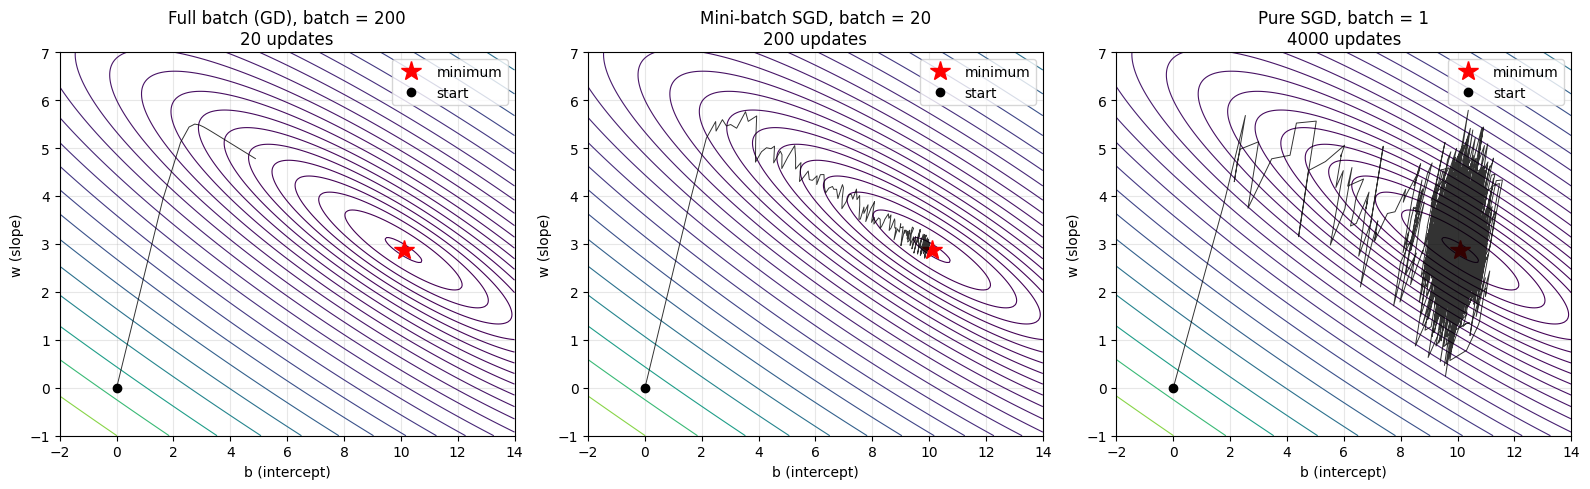

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, (path, losses)) in zip(axes, runs.items()):
    draw_contours(ax)
    ax.plot(path[:, 0], path[:, 1], "-", color="black", linewidth=0.7, alpha=0.8)
    ax.plot(path[0, 0], path[0, 1], "ko", markersize=6, label="start")
    ax.set_title(f"{name}\n{len(path) - 1} updates")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

**What do we see?**

* **Full batch:** a smooth, careful path, but after 20 epochs it has taken only **20 steps** and is still far from the minimum.
* **Batch = 1:** a jittery path (each step is based on one person only!), but it took **4000 steps** for the same cost and reached the minimum region after about one epoch. It then keeps **bouncing around** the minimum instead of settling.
* **Batch = 20:** the best of both: 200 steps, fairly smooth, and it ends closest to the minimum.

Same picture in terms of the loss, epoch by epoch (each epoch costs the same for all three methods):

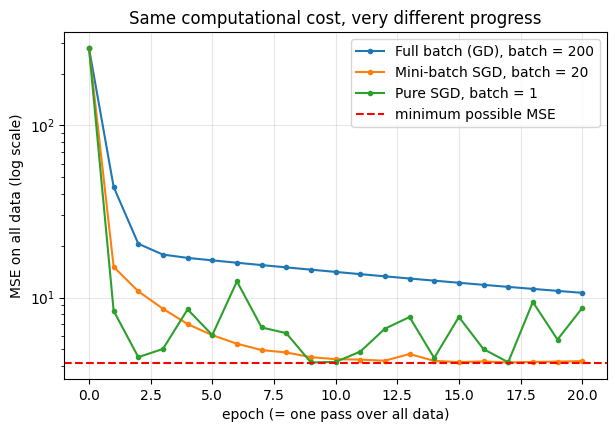

In [12]:
plt.figure(figsize=(7, 4.5))
for name, (path, losses) in runs.items():
    plt.plot(range(n_epochs + 1), losses, "o-", markersize=3, label=name)
plt.axhline(mse(x, y, b_ols, w_ols), color="red", linestyle="--", label="minimum possible MSE")
plt.yscale("log")
plt.xlabel("epoch (= one pass over all data)")
plt.ylabel("MSE on all data (log scale)")
plt.title("Same computational cost, very different progress")
plt.legend()
plt.show()

## 1.5 The price of noise: SGD never quite settles

Let's zoom in on the minimum and run pure SGD (batch = 1) for 50 epochs, with a smaller learning rate (0.02).

With a **constant** learning rate, SGD keeps jumping around the minimum: each single data point "pulls" the parameters in its own direction.
A common fix is to **decrease the learning rate** over time: big steps at the beginning, small careful steps at the end.
Here: $\eta_{\text{epoch}} = \dfrac{\eta_0}{1 + 0.3 \cdot \text{epoch}}$.

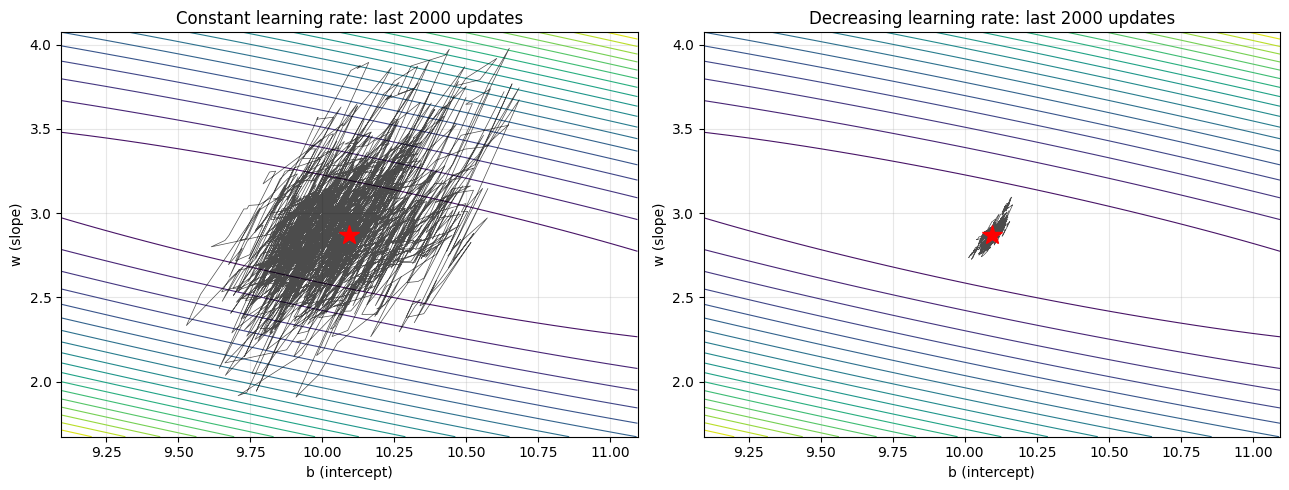

In [13]:
path_const, _ = sgd(x, y, batch_size=1, lr=0.02, n_epochs=50)
path_decay, _ = sgd(x, y, batch_size=1, lr=0.02, n_epochs=50, decay=0.3)

# a finer grid around the minimum
B_zoom, W_zoom = np.meshgrid(np.linspace(b_ols - 1, b_ols + 1, 150), np.linspace(w_ols - 1.2, w_ols + 1.2, 150))
L_zoom = np.mean((y[None, None, :] - (B_zoom[..., None] + W_zoom[..., None] * x[None, None, :])) ** 2, axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, path, title in zip(axes, [path_const, path_decay], ["Constant learning rate", "Decreasing learning rate"]):
    last = path[-2000:]                              # the last 2000 updates (10 epochs)
    ax.contour(B_zoom, W_zoom, L_zoom, levels=20, cmap="viridis", linewidths=0.8)
    ax.plot(last[:, 0], last[:, 1], "-", color="black", linewidth=0.5, alpha=0.7)
    ax.plot(b_ols, w_ols, "r*", markersize=15)
    ax.set_xlim(b_ols - 1, b_ols + 1)                # same zoom window in both panels
    ax.set_ylim(w_ols - 1.2, w_ols + 1.2)
    ax.set_title(f"{title}: last 2000 updates")
    ax.set_xlabel("b (intercept)")
    ax.set_ylabel("w (slope)")
plt.tight_layout()
plt.show()

## 1.6 SGD on a rough surface

So far our loss surface was a simple bowl: linear regression with MSE is **convex**, so it has exactly one minimum, and any reasonable method will find it. The noise in SGD was purely a cost: something we had to tame with a decaying learning rate.

Neural networks are different. Their loss surfaces are **non-convex**: full of hills, valleys and **local minima**, points where the gradient is zero but the loss is not the lowest possible. Gradient descent only ever looks at the slope right where it stands, so once it rolls into such a valley, it has no reason to leave.

To see this, we use a small model with only two parameters, the **Gabor model** (this example follows S. J. D. Prince, *Understanding Deep Learning*, Chapter 6):

$$f(x; \phi_0, \phi_1) = \sin(\phi_0 + 0.06\,\phi_1 x)\cdot \exp\!\left(-\frac{(\phi_0 + 0.06\,\phi_1 x)^2}{32}\right)$$

It is a sine wave multiplied by a bell curve: $\phi_0$ shifts the wave left and right, $\phi_1$ stretches or squeezes it. Fitting this wavy curve to data gives a loss surface with several valleys, which we can still draw as a contour map because there are only two parameters.

We start full-batch GD and mini-batch SGD from the **same point** and compare where they end up.

In [34]:
rng_g = np.random.default_rng(1)
n_g = 40
x_g = rng_g.uniform(-15, 15, size=n_g)
phi_true = np.array([0.0, 10.0])

def gabor_model(phi, x):
    # a sine wave multiplied by a bell curve; phi[0] shifts it, phi[1] stretches it
    a = phi[0] + 0.06 * phi[1] * x
    return np.sin(a) * np.exp(-a ** 2 / 32)

y_g = gabor_model(phi_true, x_g) + rng_g.normal(0, 0.1, size=n_g)

In [35]:
def gabor_loss(phi, x, y):
    return np.mean((gabor_model(phi, x) - y) ** 2)

def gabor_gradient(phi, x, y):
    a = phi[0] + 0.06 * phi[1] * x
    bell = np.exp(-a ** 2 / 32)
    # derivative of the model w.r.t. a (chain rule)
    df_da = bell * (np.cos(a) - a * np.sin(a) / 16)
    residual = 2 * (gabor_model(phi, x) - y)
    # da/dphi0 = 1
    grad_phi0 = np.mean(residual * df_da)
    # da/dphi1 = 0.06 x
    grad_phi1 = np.mean(residual * df_da * 0.06 * x)
    return np.array([grad_phi0, grad_phi1])

In [36]:
# SGD with batch size
def gabor_sgd(phi0, batch_size, lr, n_epochs, decay=0.0, seed=0):
    rng = np.random.default_rng(seed)
    phi = np.array(phi0, dtype=float)
    path = [phi.copy()]
    for epoch in range(n_epochs):
        lr_epoch = lr / (1 + decay * epoch)
        order = rng.permutation(n_g)
        for start in range(0, n_g, batch_size):
            batch = order[start : start + batch_size]
            phi = phi - lr_epoch * gabor_gradient(phi, x_g[batch], y_g[batch])
            path.append(phi.copy())
    return np.array(path)

start = (3.0, 18.0)

# Full-batch GD: 2000 steps (many more updates than SGD gets below)
path_gd = gabor_sgd(start, batch_size=n_g, lr=2.0, n_epochs=2000)

# Mini-batch SGD: batch of 5, 80 epochs (= 640 updates), decaying learning rate
path_sgd = gabor_sgd(start, batch_size=5, lr=3.0, n_epochs=80, decay=0.05, seed=1)

# Same SGD settings, 30 different random seeds: where do they end up?
ends_sgd = np.array([gabor_sgd(start, batch_size=5, lr=3.0, n_epochs=80, decay=0.05, seed=s)[-1] for s in range(30)])
n_global = np.sum(np.linalg.norm(ends_sgd - phi_true, axis=1) < 1)

for name, path in [("GD ", path_gd), ("SGD", path_sgd)]:
    print(f"{name}: ends at phi = ({path[-1, 0]:5.2f}, {path[-1, 1]:5.2f}),  loss = {gabor_loss(path[-1], x_g, y_g):.4f}")
print(f"SGD with 30 different seeds: {n_global}/30 reach the global minimum")

GD : ends at phi = ( 1.07, 22.50),  loss = 0.1694
SGD: ends at phi = ( 0.02, 10.03),  loss = 0.0055
SGD with 30 different seeds: 26/30 reach the global minimum


In [37]:
P0, P1 = np.meshgrid(np.linspace(-10, 10, 300), np.linspace(2.5, 27.5, 300))
A = P0[..., None] + 0.06 * P1[..., None] * x_g
L_g = np.mean((np.sin(A) * np.exp(-A ** 2 / 32) - y_g) ** 2, axis=-1)

def gabor_contours(ax, title):
    cs = ax.contourf(P0, P1, L_g, levels=30, cmap="viridis")   # dark = low loss
    plt.colorbar(cs, ax=ax, label="loss (MSE)")
    ax.contour(P0, P1, L_g, levels=30, colors="k", linewidths=0.3, alpha=0.5)
    ax.plot(*phi_true, "r*", markersize=18, markeredgecolor="w", label="global minimum")
    ax.plot(*start, "wo", markersize=9, markeredgecolor="k", label="start")
    ax.set_xlabel(r"$\phi_0$ (shift)")
    ax.set_ylabel(r"$\phi_1$ (stretch)")
    ax.set_title(title)

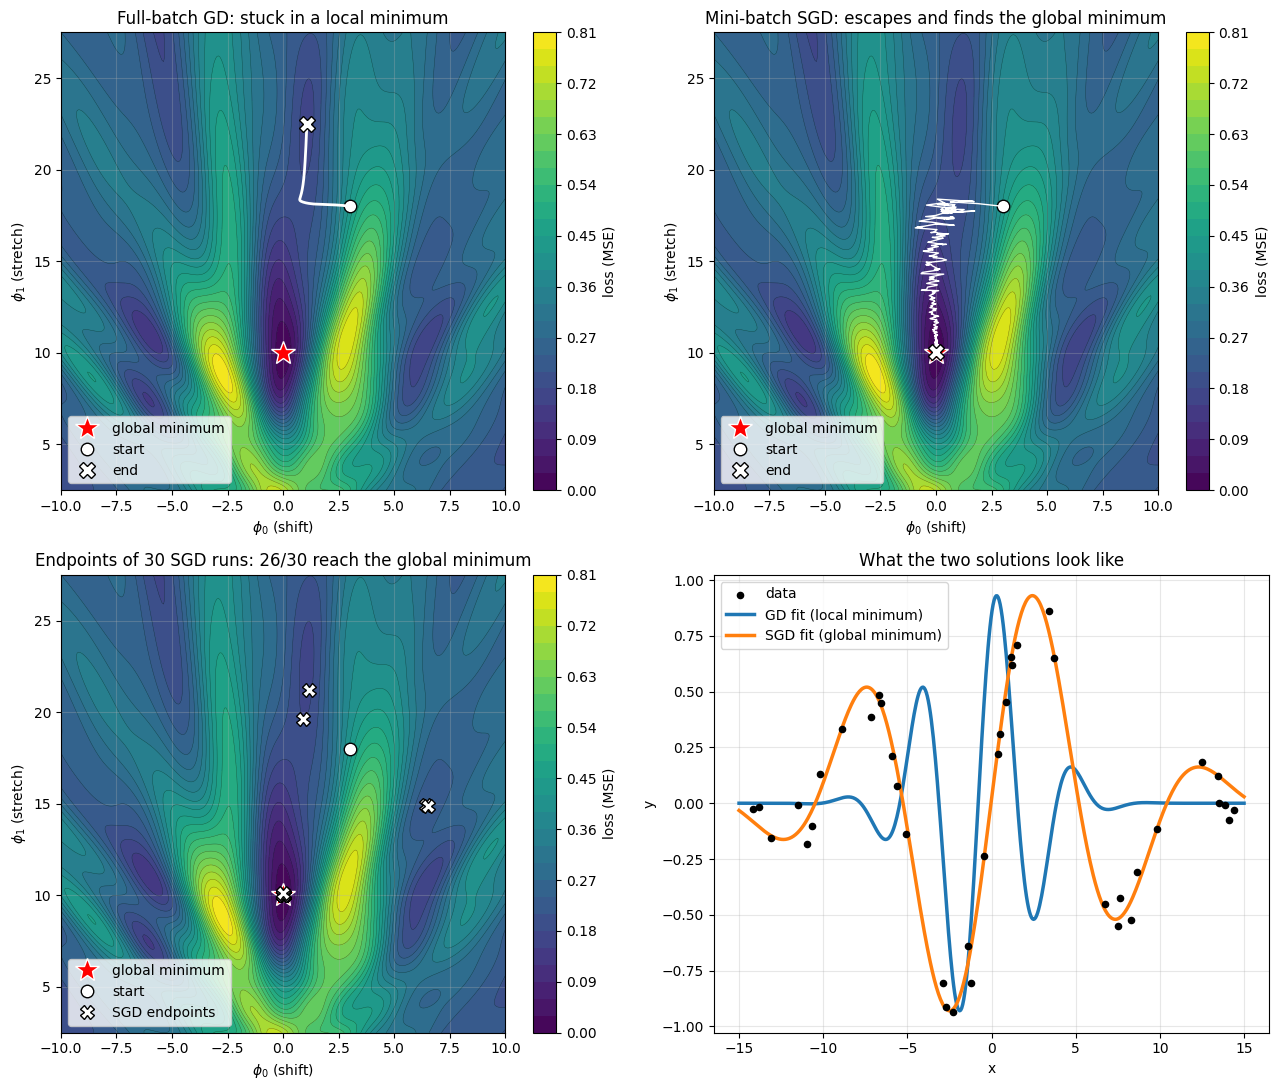

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))

ax = axes[0, 0]
gabor_contours(ax, "Full-batch GD: stuck in a local minimum")
ax.plot(path_gd[:, 0], path_gd[:, 1], "w-", linewidth=2)
ax.plot(*path_gd[-1], "wX", markersize=12, markeredgecolor="k", label="end")
ax.legend(loc="lower left")

ax = axes[0, 1]
gabor_contours(ax, "Mini-batch SGD: escapes and finds the global minimum")
ax.plot(path_sgd[:, 0], path_sgd[:, 1], "w-", linewidth=1)
ax.plot(*path_sgd[-1], "wX", markersize=12, markeredgecolor="k", label="end")
ax.legend(loc="lower left")

ax = axes[1, 0]
gabor_contours(ax, f"Endpoints of 30 SGD runs: {n_global}/30 reach the global minimum")
ax.plot(ends_sgd[:, 0], ends_sgd[:, 1], "wX", markersize=10, markeredgecolor="k", label="SGD endpoints")
ax.legend(loc="lower left")

ax = axes[1, 1]
x_plot = np.linspace(-15, 15, 500)
ax.scatter(x_g, y_g, color="k", s=20, zorder=3, label="data")
ax.plot(x_plot, gabor_model(path_gd[-1], x_plot), linewidth=2.5, label="GD fit (local minimum)")
ax.plot(x_plot, gabor_model(path_sgd[-1], x_plot), linewidth=2.5, label="SGD fit (global minimum)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("What the two solutions look like")
ax.legend()

plt.tight_layout()
plt.show()

**What do we see?**

* **GD** follows the slope smoothly downhill into the nearest valley. That valley is a local minimum: the gradient there is zero, so GD stops for good, even after 2000 steps. The fitted curve (bottom right) clearly does not match the data.
* **SGD** starts at the same place, but each mini-batch gives a slightly different, noisy gradient. These random kicks are enough to push it out of the shallow valley, and it ends in the global minimum with a curve that fits the data well.
* SGD is **not guaranteed** to escape: with 30 different random seeds, most runs reach the global minimum, but a few still get stuck. Noise makes escaping *more likely*, not certain.

**The key idea:** on the convex regression problem, SGD's noise was a nuisance. On a non-convex surface, the same noise becomes an **advantage**, because it helps the parameters escape poor local minima. Since the loss of every neural network is non-convex, this is one more reason mini-batch SGD and its descendants are the standard way to train them.

### Summary of Part 1

| | full batch GD | mini-batch SGD | pure SGD (batch = 1) |
|---|---|---|---|
| cost per update | high | low | lowest |
| noise in direction | none | some | a lot |
| progress per epoch | slow | fast | fast |
| used in practice | small problems | **almost always** (batch 32–512) | rarely |

Mini-batches are also what computers (and GPUs) handle most efficiently, which is why practically all of deep learning is trained with mini-batch SGD or one of its descendants (momentum, Adam, ...).

**Keep in mind:** "learning one example at a time" is pure SGD. That is exactly how the perceptron learns.

# Part 2: The Perceptron

## 2.1 The model

In 1958, Frank Rosenblatt proposed the **perceptron**, inspired by a biological neuron (We saw it on week 1):

1. take the inputs $x_1, x_2, \dots$
2. compute a weighted sum plus a bias: $z = w_1 x_1 + w_2 x_2 + b$
3. "fire" if $z$ is positive: $\hat y = \text{step}(z)$

$$\text{step}(z) = \begin{cases} 1 & z > 0 \\ 0 & z \le 0 \end{cases}$$

The `step` function is our first **activation function**: it turns the number $z$ into a decision.

Geometrically, the perceptron draws a **straight line** $w_1 x_1 + w_2 x_2 + b = 0$ and says "1" on one side and "0" on the other.

## 2.2 Our toy data: logic gates

Four points, the corners of a square. Different labelings give different "logic gates":

| $x_1$ | $x_2$ | AND | OR | XOR |
|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 |
| 1 | 1 | 1 | 1 | 0 |

*If you were a bank*: think of $x_1$ = "has a stable job", $x_2$ = "owns property".

**AND**: approve a loan only if both both are true.

**OR**: approve if at least one is true.

**XOR**: exactly one of the two is true, but not both (harder to motivate, and as we'll see, harder to learn!).

In [14]:
X_gate = np.array([[0, 0],
                   [0, 1],
                   [1, 0],
                   [1, 1]])

y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

**NumPy Exp.** `X_gate` is a 4×2 array: 4 rows (points), 2 columns (features). `X_gate[i]` is row `i`, i.e. one point.
> `X @ w` is matrix multiplication: for each row it computes $w_1 x_1 + w_2 x_2$, so for all 4 points at once.

Plotting helpers *(no need to understand the details)*: one draws the points, the other colors the regions where the model says 0 or 1.

In [16]:
# light orange = class 0, light blue = class 1
CMAP_HARD = ListedColormap(["#fdd9b5", "#c6dbef"])

def plot_points(ax, X, y, title=""):
    y = np.asarray(y)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], marker="o", s=180, c="tab:blue",   edgecolor="k", zorder=3, label="class 1")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], marker="s", s=180, c="tab:orange", edgecolor="k", zorder=3, label="class 0")
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(title)

def plot_region(ax, predict_fn, soft=False, lim=(-0.5, 1.5)):
    g = np.linspace(lim[0], lim[1], 300)
    G1, G2 = np.meshgrid(g, g)
    # 90,000 points covering the square
    grid = np.column_stack([G1.ravel(), G2.ravel()])
    Z = predict_fn(grid).reshape(G1.shape)
    if soft:
        # predictions between 0 and 1
        ax.contourf(G1, G2, Z, levels=np.linspace(0, 1, 21), cmap="RdBu", alpha=0.45)
        ax.contour(G1, G2, Z, levels=[0.5], colors="k", linewidths=2)
    else:
        # predictions are exactly 0 or 1
        ax.contourf(G1, G2, Z, levels=[-0.5, 0.5, 1.5], cmap=CMAP_HARD)

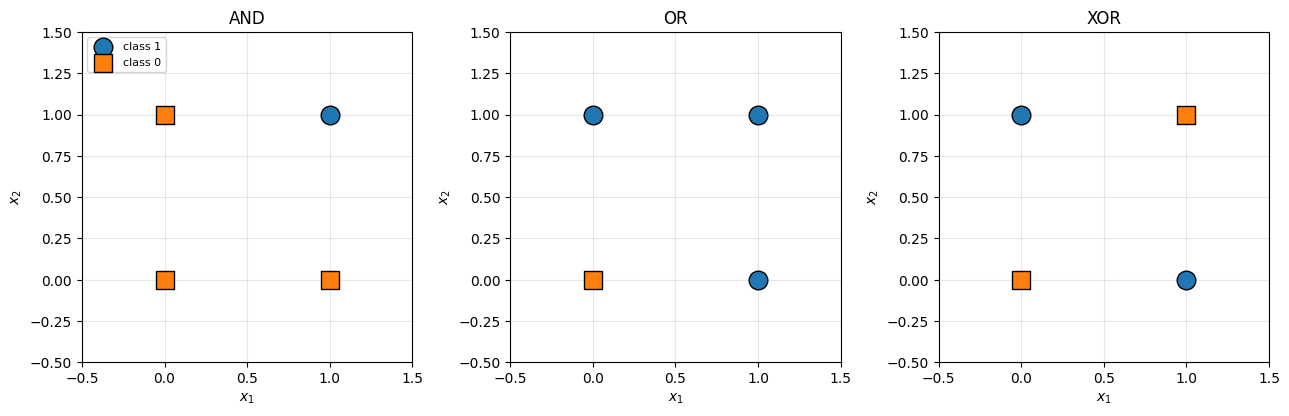

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, y_, name in zip(axes, [y_and, y_or, y_xor], ["AND", "OR", "XOR"]):
    plot_points(ax, X_gate, y_, name)
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 2.3 The perceptron learning rule

Rosenblatt's rule, applied **one example at a time**:

$$w \leftarrow w + \eta\,(y - \hat y)\,x \qquad b \leftarrow b + \eta\,(y - \hat y)$$

* correct prediction: $y - \hat y = 0$, nothing changes.
* predicted 0 but should be 1: $y - \hat y = +1$, move $w$ *towards* $x$ (makes $z$ bigger for this point).
* predicted 1 but should be 0: $y - \hat y = -1$, move $w$ *away from* $x$.

### This is SGD!

Recode the labels as $t = 2y - 1 \in \{-1, +1\}$ and define the **perceptron loss** of one example:

$$\ell(w, b) = \max\big(0,\; -t\,(w \cdot x + b)\big)$$

It is 0 when the point is on the correct side and grows linearly the more wrong we are. Its gradient for a misclassified point is $-t\,x$ (and $0$ otherwise), so an SGD step with **batch size 1** is

$$w \leftarrow w - \eta\,(-t\,x) = w + \eta\,t\,x.$$

For a misclassified point $t = y - \hat y$, so this is **exactly** Rosenblatt's rule.
The perceptron is a linear model + a step activation + a loss + pure SGD: the same recipe as before, just with different pieces.

In [18]:
def step(z):
    return np.where(np.asarray(z) > 0, 1, 0)

def perceptron_predict(X, w, b):
    return step(X @ w + b)

def perceptron_train(X, y, lr=1.0, n_epochs=20, seed=0):
    rng = np.random.default_rng(seed)
    # small random starting weights
    w = rng.normal(0, 0.1, size=X.shape[1])
    b = rng.normal(0, 0.1)
    # weights after every update
    history = [(w.copy(), b)]
    errors_per_epoch = []

    for epoch in range(n_epochs):
        errors = 0
        # one example at a time, in random order
        for i in rng.permutation(len(X)):
            y_hat = int(step(X[i] @ w + b))
            # 0 if correct, +1 or -1 if wrong
            update = lr * (y[i] - y_hat)
            w = w + update * X[i]
            b = b + update
            if update != 0:
                errors += 1
            history.append((w.copy(), b))
        errors_per_epoch.append(errors)

    return w, b, history, errors_per_epoch

## 2.4 Learning AND

In [19]:
w_and, b_and, hist_and, err_and = perceptron_train(X_gate, y_and, n_epochs=15)

print("Mistakes per epoch:", err_and)
print("Final weights: w =", np.round(w_and, 2), " b =", round(b_and, 2))
print("Predictions:", perceptron_predict(X_gate, w_and, b_and), "  targets:", y_and)

Mistakes per epoch: [4, 2, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Final weights: w = [1.01 0.99]  b = -1.94
Predictions: [0 0 0 1]   targets: [0 0 0 1]


Let's watch the decision boundary move during training:

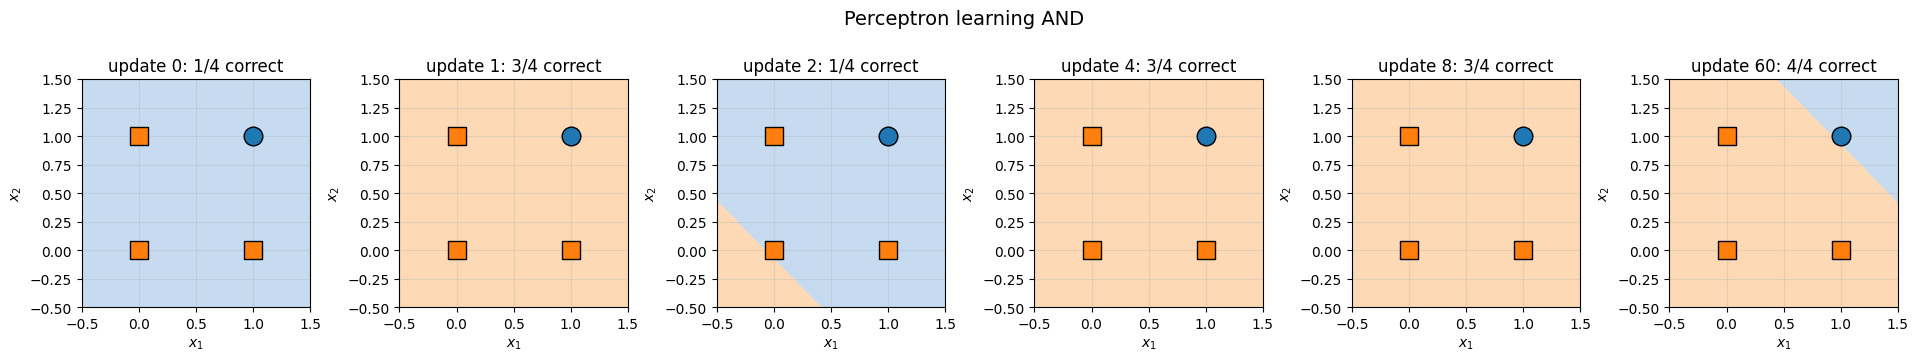

In [20]:
def show_snapshots(history, X, y, steps, title):
    fig, axes = plt.subplots(1, len(steps), figsize=(3.2 * len(steps), 3.6))
    for ax, k in zip(axes, steps):
        w, b = history[k]
        plot_region(ax, lambda G: perceptron_predict(G, w, b))
        n_correct = np.sum(perceptron_predict(X, w, b) == y)
        plot_points(ax, X, y, f"update {k}: {n_correct}/4 correct")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

n_updates = len(hist_and) - 1
show_snapshots(hist_and, X_gate, y_and, steps=[0, 1, 2, 4, 8, n_updates], title="Perceptron learning AND")

Once all four points are correct, no update ever changes the weights again: the algorithm has **converged**.

Notice also that the final line often passes **very close** to some points. The perceptron stops at the *first* line that works, not the "best" one. (Choosing the line with the widest safety margin is the idea behind Support Vector Machines.)

**Perceptron convergence theorem:** if a straight line separating the classes exists (the data is *linearly separable*), the perceptron rule is guaranteed to find one in a finite number of steps.

## 2.5 XOR: the perceptron's famous failure

Mistakes per epoch: [2, 3, 2, 3, 2, 1, 3, 3, 3, 3, 4, 4, 2, 3, 2, 2, 3, 2, 2, 2, 3, 3, 3, 2, 2, 2, 3, 3, 3, 4]


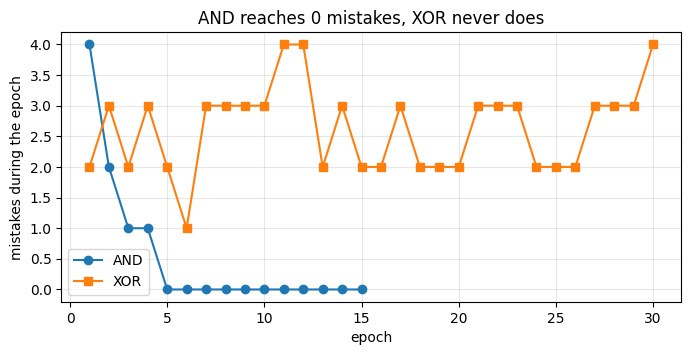

In [21]:
w_xor, b_xor, hist_xor, err_xor = perceptron_train(X_gate, y_xor, n_epochs=30)
print("Mistakes per epoch:", err_xor)

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 16), err_and[:15], "o-", label="AND")
plt.plot(range(1, 31), err_xor, "s-", label="XOR")
plt.xlabel("epoch")
plt.ylabel("mistakes during the epoch")
plt.title("AND reaches 0 mistakes, XOR never does")
plt.legend()
plt.show()

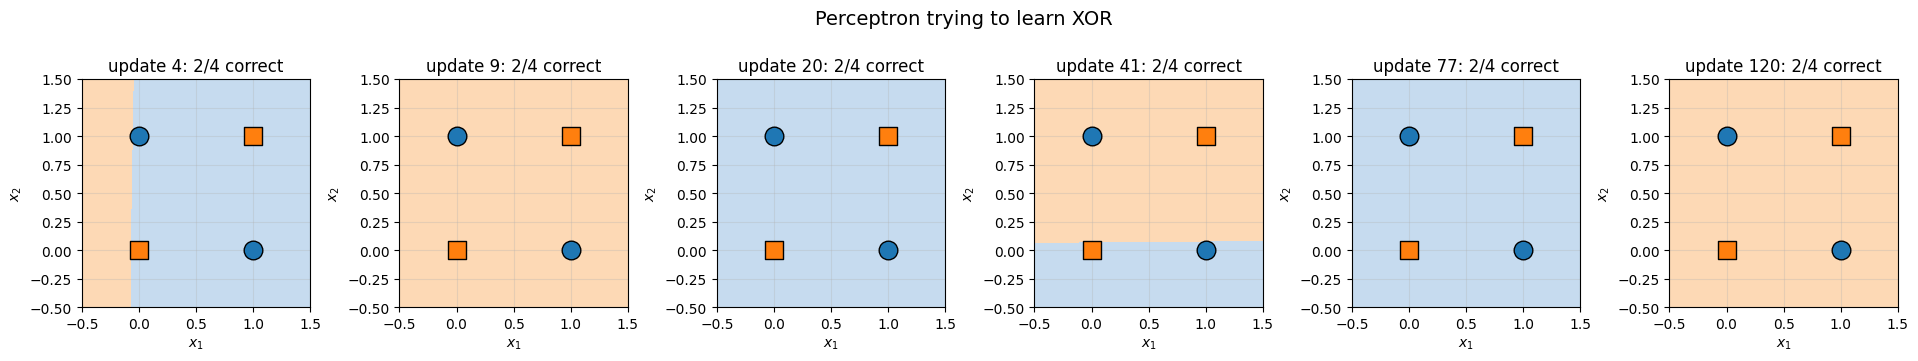

In [22]:
n_updates = len(hist_xor) - 1
show_snapshots(hist_xor, X_gate, y_xor, steps=[4, 9, 20, 41, 77, n_updates], title="Perceptron trying to learn XOR")

The line keeps moving forever: every time it fixes one point, it breaks another. As an animation:

In [23]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))

def draw_frame(k):
    ax.clear()
    w, b = hist_xor[k]
    plot_region(ax, lambda G: perceptron_predict(G, w, b))
    n_correct = np.sum(perceptron_predict(X_gate, w, b) == y_xor)
    plot_points(ax, X_gate, y_xor, f"XOR, update {k}: {n_correct}/4 correct")

anim = animation.FuncAnimation(fig, draw_frame, frames=range(0, 48), interval=400)
plt.close(fig)
HTML(anim.to_jshtml())

### Why? A one-line proof

Suppose some line $w_1 x_1 + w_2 x_2 + b$ did separate XOR. Then:

* $(0,0) \to 0$: $\;b \le 0$
* $(1,1) \to 0$: $\;w_1 + w_2 + b \le 0$
* $(0,1) \to 1$: $\;w_2 + b > 0$
* $(1,0) \to 1$: $\;w_1 + b > 0$

Adding the last two: $w_1 + w_2 + 2b > 0$. Adding the first two: $w_1 + w_2 + 2b \le 0$. **Contradiction.** No line can do it.

### A bit of history

In their 1969 book *Perceptrons*, Marvin Minsky and Seymour Papert carefully analyzed what single-layer perceptrons can and cannot compute. XOR became the symbol of these limits. They knew that networks with *more layers* could compute XOR, but nobody had a good way to **train** such networks. The book is often credited with cooling enthusiasm (and funding) for neural networks for over a decade, what came to be known as **The First AI Winter**, until the **backpropagation** algorithm became popular in 1986.

The rest of this notebook: how can we get past XOR?

# Part 3: Escaping XOR

The perceptron can only draw straight lines **in the space it sees**. So instead of changing the perceptron, we can change the space: transform the inputs first, then let a perceptron separate them.

## 3.1 Way out 1: a hand-made feature map

Add a third feature, the product $x_1 \cdot x_2$ (an *interaction term*, as you know it from econometrics):

$$\phi(x_1, x_2) = (x_1,\; x_2,\; x_1 x_2)$$

| $x_1$ | $x_2$ | $x_1 x_2$ | XOR |
|---|---|---|---|
| 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 |
| 1 | 0 | 0 | 1 |
| 1 | 1 | **1** | 0 |

The point $(1,1)$ is lifted up into the third dimension, away from the others. Let's train the *same* perceptron on these 3 features.

In [24]:
def feature_map(X):
    return np.column_stack([X[:, 0], X[:, 1], X[:, 0] * X[:, 1]])

Phi = feature_map(X_gate)
print("Transformed data:\n", Phi)

w_fm, b_fm, hist_fm, err_fm = perceptron_train(Phi, y_xor, n_epochs=20)
print("\nMistakes per epoch:", err_fm)
print("Final weights: w =", np.round(w_fm, 2), " b =", round(b_fm, 2))
print("Predictions:", perceptron_predict(Phi, w_fm, b_fm), "  targets:", y_xor)

Transformed data:
 [[0 0 0]
 [0 1 0]
 [1 0 0]
 [1 1 1]]

Mistakes per epoch: [3, 2, 2, 3, 1, 2, 1, 2, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Final weights: w = [ 1.01  1.99 -2.94]  b = -0.99
Predictions: [0 1 1 0]   targets: [0 1 1 0]


It converges! In 3D the four points are separated by a flat **plane**. Back in the original 2D picture, that plane becomes a **curved** boundary:

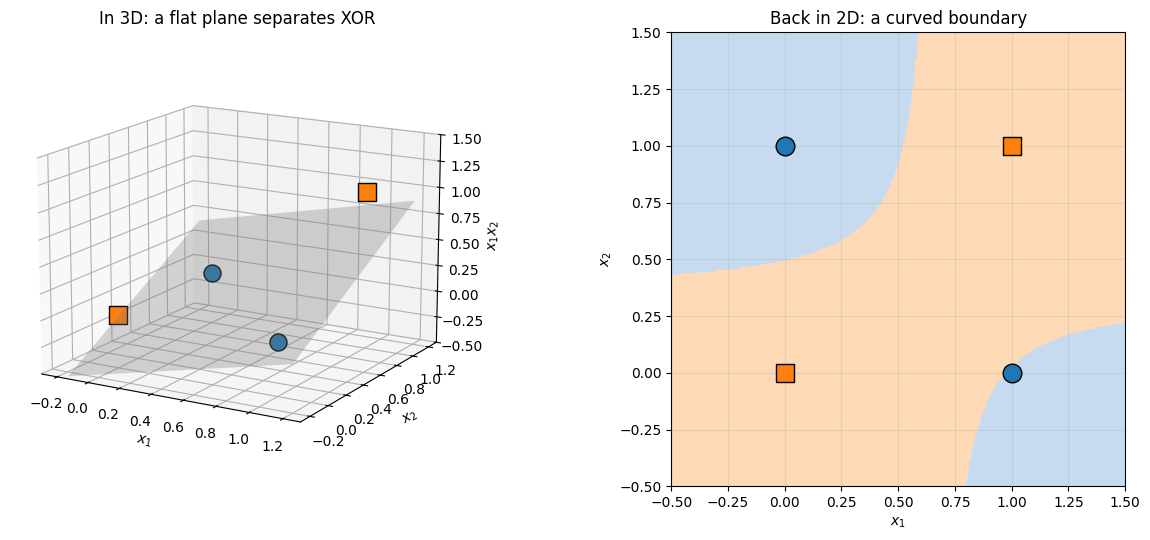

In [25]:
fig = plt.figure(figsize=(13, 5.5))

# left: 3D view with the separating plane
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
for label, marker, color in [(1, "o", "tab:blue"), (0, "s", "tab:orange")]:
    pts = Phi[y_xor == label]
    ax3d.scatter(pts[:, 0], pts[:, 1], pts[:, 2], marker=marker, s=150, c=color, edgecolor="k", depthshade=False)
p1, p2 = np.meshgrid(np.linspace(-0.2, 1.2, 10), np.linspace(-0.2, 1.2, 10))
p3 = -(w_fm[0] * p1 + w_fm[1] * p2 + b_fm) / w_fm[2]      # solve the plane equation for the 3rd coordinate
ax3d.plot_surface(p1, p2, p3, alpha=0.3, color="gray")
ax3d.set_xlabel("$x_1$"); ax3d.set_ylabel("$x_2$"); ax3d.set_zlabel("$x_1 x_2$")
ax3d.set_zlim(-0.5, 1.5)
ax3d.view_init(elev=15, azim=-60)
ax3d.set_title("In 3D: a flat plane separates XOR")

# right: the same classifier seen in the original 2D space
ax2d = fig.add_subplot(1, 2, 2)
plot_region(ax2d, lambda G: perceptron_predict(feature_map(G), w_fm, b_fm))
plot_points(ax2d, X_gate, y_xor, "Back in 2D: a curved boundary")

plt.tight_layout()
plt.show()

**The catch:** *we* had to guess the right feature. For four points that is easy. For images, text, or 200 economic indicators, which products, squares, logs, ratios should we add? There are far too many possibilities.

*(This idea of mapping data into a higher-dimensional space is also the starting point of **kernel methods** such as Support Vector Machines, which use a clever trick to avoid computing the new features explicitly.)*

What we would really like: a model that **learns its own features**. That is what a hidden layer does.

## 3.2 Way out 2: a hidden layer

Put a layer of neurons *between* the inputs and the output:

```
 inputs        hidden layer         output
  x1 ──┬──────▶  h1 ──┐
       │ ╲   ╱        ├──▶  y_hat
  x2 ──┴──────▶  h2 ──┘
```

Each hidden neuron computes $h_j = g(\text{weighted sum of the inputs} + \text{bias})$ for some function $g$, the **activation function**. The output neuron is a perceptron on $(h_1, h_2)$ instead of on $(x_1, x_2)$.

In matrix form: $\; h = g(W_1 x + b_1), \qquad \hat y = \text{step}(w_2 \cdot h + b_2)$.

### First attempt: no activation function (linear hidden layer)

Take $g(z) = z$, i.e. no activation at all. Then

$$w_2 \cdot (W_1 x + b_1) + b_2 = \underbrace{(W_1^\top w_2)}_{\text{new } w} \cdot x + \underbrace{(w_2 \cdot b_1 + b_2)}_{\text{new } b}$$

which is **again just one linear function of $x$**. Stacking linear layers gives a linear layer. Let's see it with an arbitrary $W_1$:

In [26]:
W1_lin = np.array([[ 1.0, 2.0],
                   [-1.0, 1.0]])
b1_lin = np.array([0.5, -0.3])

H_lin = X_gate @ W1_lin.T + b1_lin      # linear hidden layer, no activation
print("Hidden representation:\n", H_lin)

_, _, _, err_lin = perceptron_train(H_lin, y_xor, n_epochs=30)
print("\nMistakes per epoch:", err_lin)

Hidden representation:
 [[ 0.5 -0.3]
 [ 2.5  0.7]
 [ 1.5 -1.3]
 [ 3.5 -0.3]]

Mistakes per epoch: [2, 3, 2, 3, 4, 4, 3, 2, 3, 4, 4, 2, 2, 4, 4, 4, 3, 2, 1, 1, 3, 3, 3, 3, 2, 3, 3, 3, 4, 4]


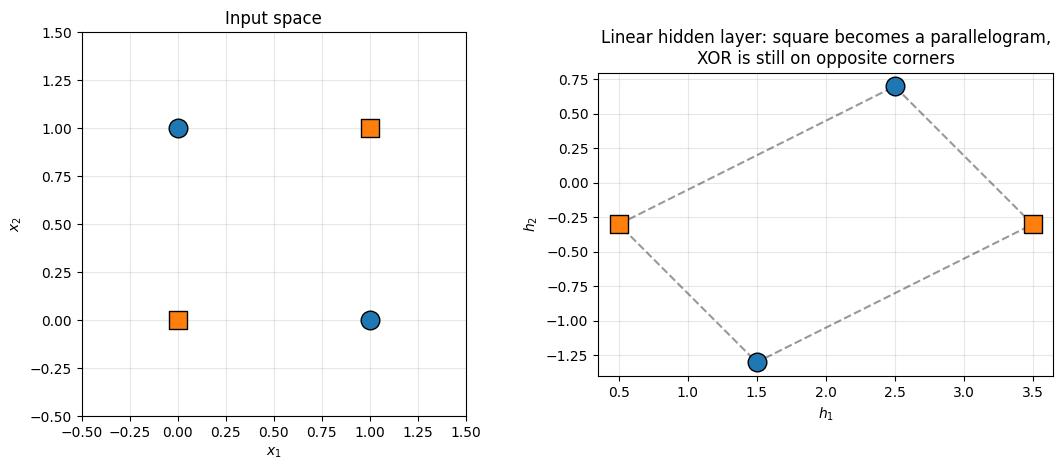

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
plot_points(axes[0], X_gate, y_xor, "Input space")

ax = axes[1]
ax.scatter(H_lin[y_xor == 1, 0], H_lin[y_xor == 1, 1], marker="o", s=180, c="tab:blue", edgecolor="k", zorder=3)
ax.scatter(H_lin[y_xor == 0, 0], H_lin[y_xor == 0, 1], marker="s", s=180, c="tab:orange", edgecolor="k", zorder=3)
order = [0, 1, 3, 2, 0]                                  # walk around the square
ax.plot(H_lin[order, 0], H_lin[order, 1], "k--", alpha=0.4)
ax.set_aspect("equal")
ax.set_xlabel("$h_1$"); ax.set_ylabel("$h_2$")
ax.set_title("Linear hidden layer: square becomes a parallelogram,\nXOR is still on opposite corners")
plt.tight_layout()
plt.show()

A linear map can stretch, rotate and shift the square, but the two blue points always stay on **opposite corners**. Still not separable.

**The non-linearity is essential.** Without an activation function, a network with 100 layers is no more powerful than a single perceptron.

### Second attempt: hidden layer with a step activation

Now use $g = \text{step}$. We choose the weights **by hand** (we'll see why below):

* $h_1 = \text{step}(x_1 + x_2 - 0.5)$: fires if **at least one** input is 1, i.e. **OR**
* $h_2 = \text{step}(-x_1 - x_2 + 1.5)$: fires **unless both** inputs are 1, i.e. **NAND** (not-and)

And XOR = "OR and NAND": at least one, but not both.

In [29]:
W1 = np.array([[ 1.0,  1.0],     # weights of h1 (OR)
               [-1.0, -1.0]])    # weights of h2 (NAND)
b1 = np.array([-0.5, 1.5])

def hidden_layer(X):
    return step(X @ W1.T + b1)

H = hidden_layer(X_gate)

print(" x1  x2 |  h1  h2 | XOR")
print("--------+---------+----")
for xi, hi, yi in zip(X_gate, H, y_xor):
    print(f" {xi[0]:2d}  {xi[1]:2d} |  {hi[0]:2d}  {hi[1]:2d} |  {yi}")

 x1  x2 |  h1  h2 | XOR
--------+---------+----
  0   0 |   0   1 |  0
  0   1 |   1   1 |  1
  1   0 |   1   1 |  1
  1   1 |   1   0 |  0


In the hidden space, the two blue points land on the **same** spot $(1, 1)$, and the orange points on $(0,1)$ and $(1,0)$.
Now a straight line works. We can even **train** the output neuron with the ordinary perceptron rule, on $h$ instead of $x$:

In [30]:
w_out, b_out, _, err_out = perceptron_train(H, y_xor, n_epochs=20)
print("Mistakes per epoch:", err_out)
print("Output weights: w =", np.round(w_out, 2), " b =", round(b_out, 2))

def network_predict(X):
    return perceptron_predict(hidden_layer(X), w_out, b_out)

print("Network predictions:", network_predict(X_gate), "  targets:", y_xor)

Mistakes per epoch: [2, 3, 1, 2, 3, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Output weights: w = [1.01 1.99]  b = -2.94
Network predictions: [0 1 1 0]   targets: [0 1 1 0]


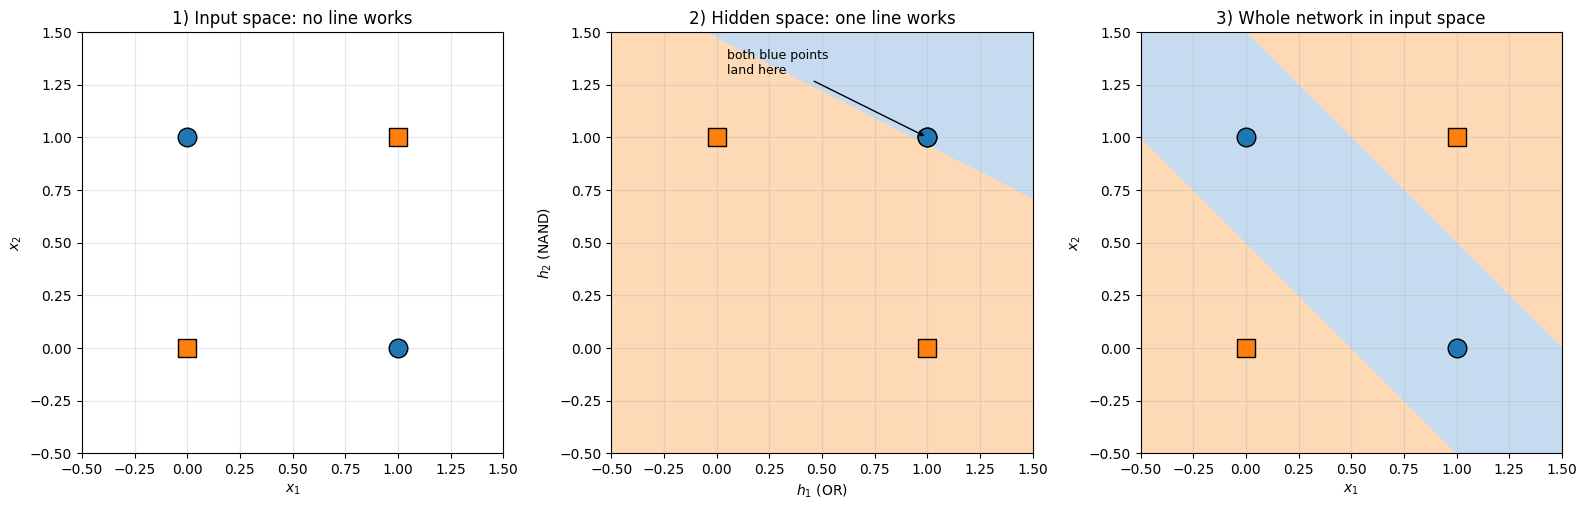

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1) input space: not separable
plot_points(axes[0], X_gate, y_xor, "1) Input space: no line works")

# 2) hidden space: separable, with the output neuron's boundary
ax = axes[1]
plot_region(ax, lambda G: perceptron_predict(G, w_out, b_out))
plot_points(ax, H, y_xor, "2) Hidden space: one line works")
ax.set_xlabel("$h_1$ (OR)"); ax.set_ylabel("$h_2$ (NAND)")
ax.annotate("both blue points\nland here", xy=(1, 1), xytext=(0.05, 1.3),
            arrowprops=dict(arrowstyle="->"), fontsize=9)

# 3) the whole network, seen in input space
plot_region(axes[2], network_predict)
plot_points(axes[2], X_gate, y_xor, "3) Whole network in input space")

plt.tight_layout()
plt.show()

Panel 3 shows what the network really does: two straight lines (one per hidden neuron) whose combination cuts out a **band**. Neither neuron alone can solve XOR; together they can.

**Compare the two ways out:**

| | feature map | hidden layer |
|---|---|---|
| new features | $x_1 x_2$, chosen by **us** | $h_1, h_2$, computed by neurons with weights |
| what makes it non-linear | the product | the **activation function** |
| could the features be learned? | no | **yes**, in principle, by adjusting $W_1, b_1$ |

### The remaining problem

We chose $W_1$ and $b_1$ **by hand**. Could we learn them with gradient descent instead, like everything else so far?

Not with the step function. Its derivative is **0 everywhere** (except at $z=0$, where it is undefined). If we nudge a weight a little, the output does not change at all, so the gradient carries no information on which direction to move.

We need activation functions that are non-linear **and** have useful derivatives.

---
# Part 4: Activation functions at a glance

| name | formula | derivative | output range |
|---|---|---|---|
| step | $1$ if $z>0$, else $0$ | $0$ | $\{0, 1\}$ |
| sigmoid | $\sigma(z) = \dfrac{1}{1+e^{-z}}$ | $\sigma(z)(1-\sigma(z))$ | $(0, 1)$ |
| tanh | $\tanh(z)$ | $1 - \tanh^2(z)$ | $(-1, 1)$ |
| ReLU | $\max(0, z)$ | $1$ if $z>0$, else $0$ | $[0, \infty)$ |

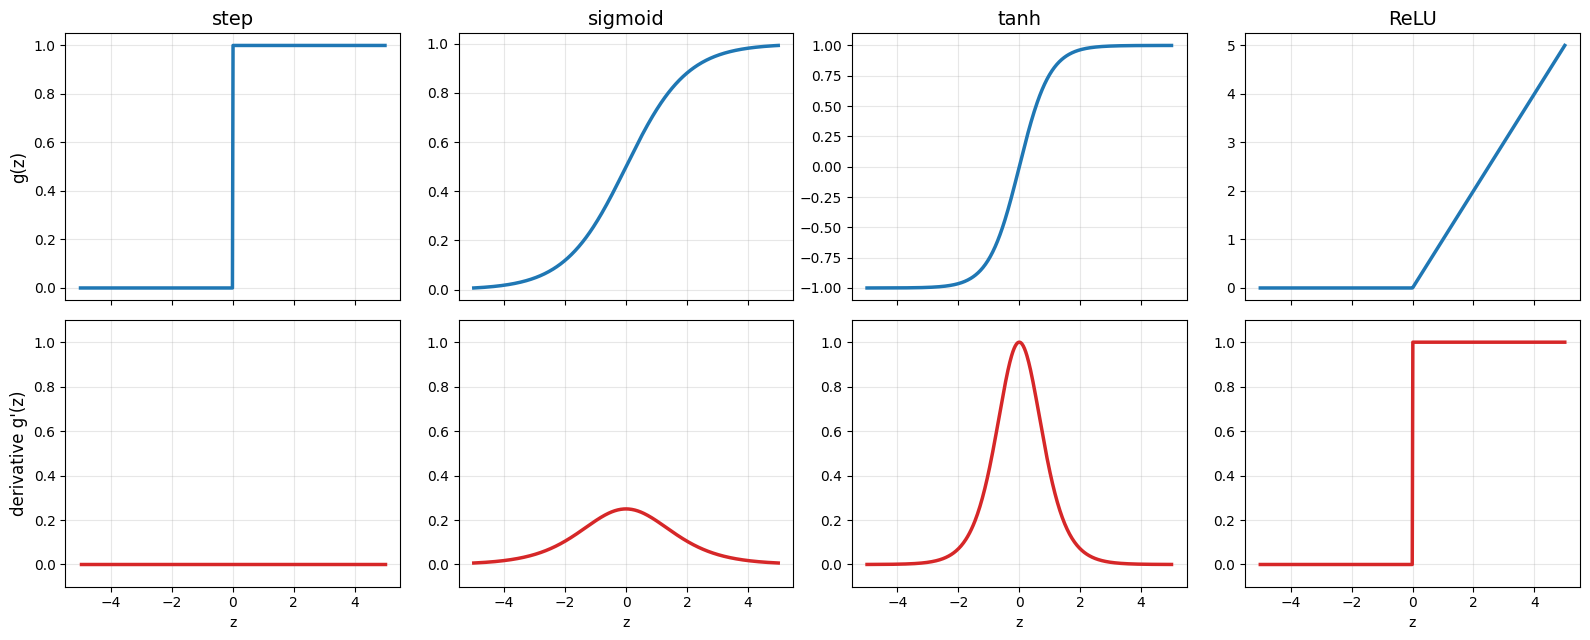

In [32]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

z = np.linspace(-5, 5, 500)

activations = {
    "step":    (step(z),        np.zeros_like(z)),
    "sigmoid": (sigmoid(z),     sigmoid(z) * (1 - sigmoid(z))),
    "tanh":    (np.tanh(z),     1 - np.tanh(z) ** 2),
    "ReLU":    (relu(z),        (z > 0).astype(float)),
}

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for col, (name, (g, dg)) in enumerate(activations.items()):
    axes[0, col].plot(z, g, linewidth=2.5)
    axes[0, col].set_title(name, fontsize=14)
    axes[1, col].plot(z, dg, linewidth=2.5, color="tab:red")
    axes[1, col].set_xlabel("z")
axes[0, 0].set_ylabel("g(z)", fontsize=12)
axes[1, 0].set_ylabel("derivative g'(z)", fontsize=12)
for ax in axes[1]:
    ax.set_ylim(-0.1, 1.1)
plt.tight_layout()
plt.show()

**Things to notice:**

* **step**: derivative is 0 everywhere, so gradient descent cannot learn through it.
* **sigmoid**: a smooth version of the step. You already know it: it is the **logit model** from econometrics (and, together with cross-entropy, logistic regression is just a single neuron with a sigmoid!). Its derivative is at most **0.25** and almost 0 for large $|z|$; keep that in mind for next time.
* **tanh**: like sigmoid but centered at 0. Derivative up to 1, still flat at the ends.
* **ReLU**: the default choice in modern networks. Simple, cheap, and the derivative is exactly 1 for every positive input.

## 4.1 XOR with sigmoid neurons

Replace every `step` in our network with a sigmoid. Since $\sigma(k z)$ looks more and more like a step as $k$ grows, we multiply our hand-picked weights by a factor $k$:

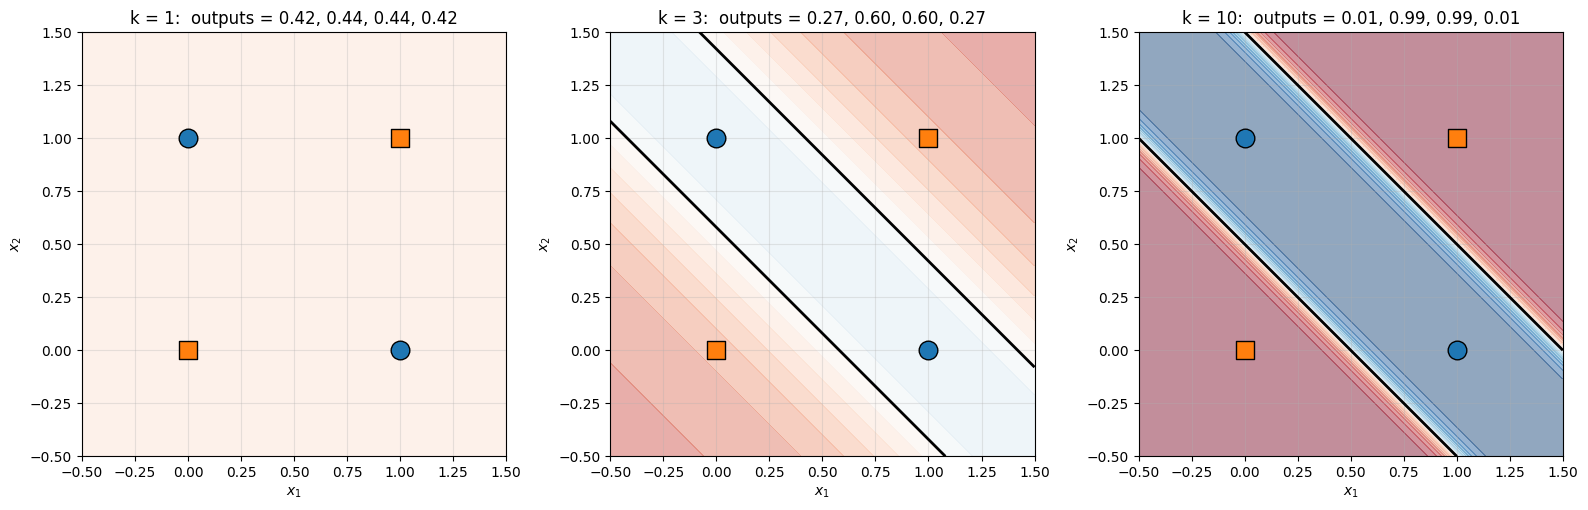

In [33]:
w2_hand = np.array([1.0, 1.0])     # output neuron: AND of h1 and h2
b2_hand = -1.5

def sigmoid_network(X, k):
    h = sigmoid(k * (X @ W1.T + b1))
    return sigmoid(k * (h @ w2_hand + b2_hand))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, k in zip(axes, [1, 3, 10]):
    plot_region(ax, lambda G: sigmoid_network(G, k), soft=True)
    outputs = sigmoid_network(X_gate, k)
    plot_points(ax, X_gate, y_xor, f"k = {k}:  outputs = " + ", ".join(f"{o:.2f}" for o in outputs))
plt.tight_layout()
plt.show()

* With **k = 1** the outputs are all close to 0.5: the network is very unsure.
* With **k = 10** it behaves almost exactly like the step network, but now everything is **smooth**: a small change in any weight gives a small change in the output.

Smooth means we can take derivatives. Derivatives mean we can use gradient descent, and that means the network could, in principle, **learn $W_1$ and $b_1$ by itself** instead of us choosing them.

---
# Summary

1. **SGD** estimates the gradient from a small mini-batch. Noisier steps, but far more of them for the same cost. Mini-batch SGD is how essentially all neural networks are trained.
2. The **perceptron** = linear model + step activation, trained by pure SGD on the perceptron loss. It finds a separating line whenever one exists.
3. **XOR** has no separating line, so a single perceptron fails, forever.
4. Transforming the inputs fixes this: either with **hand-made features** ($x_1 x_2$), or with a **hidden layer**.
5. A hidden layer only helps if it has a **non-linear activation function**. Without it, layers collapse into one linear model.
6. To *learn* the hidden weights by gradient descent, the activation needs useful **derivatives**: sigmoid, tanh, ReLU instead of step.

## Next time: backpropagation

We still picked the hidden weights by hand. How do we compute $\dfrac{\partial L}{\partial W_1}$ when $W_1$ sits *behind* another layer? The answer is the chain rule, organized efficiently: **backpropagation**. And the derivatives of the activation functions above will appear in every step of it.

---
# Exercises

1. **Batch size and learning rate.** In section 1.4, try `batch_size=50` and learning rates `0.01`, `0.1`, `0.2`. What happens with full-batch GD at `lr=0.2`? What about pure SGD?
2. **More gates.** Train the perceptron on **NAND** (`[1, 1, 1, 0]`). Does it converge? Draw the final boundary.
3. **Another feature map.** Instead of $x_1 x_2$, use $(x_1 - x_2)^2$ as the third feature. Does the perceptron now learn XOR? Why?
4. **Another hidden layer.** XOR is also "($x_1$ AND NOT $x_2$) OR (NOT $x_1$ AND $x_2$)". Choose weights for two hidden step neurons computing these, and an output neuron computing OR. Check your network on all four points.
5. **Sigmoid sharpness.** In section 4.1, what is the smallest $k$ for which all four outputs are on the correct side of 0.5?